<a href="https://colab.research.google.com/github/abdullah-hattab/Student-Performance-EDA/blob/main/Student_Performance_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [106]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/StudentsPerformance.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [107]:
df.columns = (df.columns.str.strip().str.lower().str.replace("[ /]", "_", regex=True))

In [108]:
df.head()


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [110]:
print ("| gender | Student's gender (female / male) |\n"
"| race/ethnicity | Anonymized group label (group A – group E); the real categories were not published |\n"
"| parental level of education | Highest education level reached by the student's parents |\n"
"| lunch | Meal program the student is on (standard / free-reduced) — an indicator of family income |\n"
"| test preparation course | Whether the student completed a preparation course (none / completed) |\n"
"| math score | Math exam score (0–100) |\n"
"| reading score | Reading exam score (0–100) |\n"
"| writing score | Writing exam score (0–100) |\n")

| gender | Student's gender (female / male) |
| race/ethnicity | Anonymized group label (group A – group E); the real categories were not published |
| parental level of education | Highest education level reached by the student's parents |
| lunch | Meal program the student is on (standard / free-reduced) — an indicator of family income |
| test preparation course | Whether the student completed a preparation course (none / completed) |
| math score | Math exam score (0–100) |
| reading score | Reading exam score (0–100) |
| writing score | Writing exam score (0–100) |



In [111]:
print ("from the previous df.info() function, we can tell that there is no missing value")

from the previous df.info() function, we can tell that there is no missing value


In [112]:
print (f"Number of duplicate rows found: {df.duplicated().sum()}")

Number of duplicate rows found: 0


In [113]:
print (f"Number of Null Value: {df.isnull().sum()}")

Number of Null Value: gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64


In [114]:
for c in df.columns:
  print (f"{c}:-\n{df[c].value_counts()}")


gender:-
gender
female    518
male      482
Name: count, dtype: int64
race_ethnicity:-
race_ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64
parental_level_of_education:-
parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64
lunch:-
lunch
standard        645
free/reduced    355
Name: count, dtype: int64
test_preparation_course:-
test_preparation_course
none         642
completed    358
Name: count, dtype: int64
math_score:-
math_score
65    36
62    35
69    32
59    32
73    27
      ..
24     1
26     1
19     1
23     1
8      1
Name: count, Length: 81, dtype: int64
reading_score:-
reading_score
72    34
74    33
64    32
73    30
67    30
      ..
32     1
26     1
28     1
23     1
40     1
Name: count, Length: 72, dtype: int64
writing_score:-
writing_score
74    35


In [115]:
print (f"Numrical Columns :{df.select_dtypes(include='number').columns.tolist()}\nObject Columns: {df.select_dtypes(include="object").columns.tolist()}")

Numrical Columns :['math_score', 'reading_score', 'writing_score']
Object Columns: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [116]:
df[["math_score", "reading_score", "writing_score"]].describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [117]:
for c in ["math_score", "reading_score", "writing_score"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[c] < low) | (df[c] > high)]
    print(f"{c}: bounds ({low:}), {high}) -> {len(out)} outliers: {sorted(out[c].tolist())}")
print ("All Outliers are in range of 0 and 100 which is valid range, they are genuine low scores rather than just an error, so we don't remove them or replace them")

math_score: bounds (27.0), 107.0) -> 8 outliers: [0, 8, 18, 19, 22, 23, 24, 26]
reading_score: bounds (29.0), 109.0) -> 6 outliers: [17, 23, 24, 24, 26, 28]
writing_score: bounds (25.875), 110.875) -> 5 outliers: [10, 15, 19, 22, 23]
All Outliers are in range of 0 and 100 which is valid range, they are genuine low scores rather than just an error, so we don't remove them or replace them


In [118]:
print ("The Data set is clear, and the checks above shows that")

The Data set is clear, and the checks above shows that


In [119]:
df["pass_math"] = df["math_score"] >= 50
df["pass_math"].value_counts()

,count
pass_math,
True,865
False,135


In [120]:
df["average_score"] = (df["math_score"] + df["reading_score"] + df["writing_score"]) / 3
df["performance_level"] = pd.cut(df["average_score"],bins=[0,50,75,101],labels=["low","medium","high"])
print (df["average_score"].describe())
print ()
print (df["performance_level"].value_counts())

count    1000.000000
mean       67.770667
std        14.257326
min         9.000000
25%        58.333333
50%        68.333333
75%        77.666667
max       100.000000
Name: average_score, dtype: float64

performance_level
medium    578
high      313
low       109
Name: count, dtype: int64


In [121]:
print("Shape:", df.shape)
print("\nData types:"); print(df.dtypes)
display(df.head())

Shape: (1000, 11)

Data types:
gender                           object
race_ethnicity                   object
parental_level_of_education      object
lunch                            object
test_preparation_course          object
math_score                        int64
reading_score                     int64
writing_score                     int64
pass_math                          bool
average_score                   float64
performance_level              category
dtype: object


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,pass_math,average_score,performance_level
0,female,group B,bachelor's degree,standard,none,72,72,74,True,72.666667,medium
1,female,group C,some college,standard,completed,69,90,88,True,82.333333,high
2,female,group B,master's degree,standard,none,90,95,93,True,92.666667,high
3,male,group A,associate's degree,free/reduced,none,47,57,44,False,49.333333,low
4,male,group C,some college,standard,none,76,78,75,True,76.333333,high


In [122]:
print ("Decisions: The Pass mark set at 50, so pass math is true when math_score >= 50\n"
"Perforamnce_level set as follow, when the average score is below 50, the peroframnce_level set at low, between 50 and 75 considered as medium, and from 75 to 100 considered as high")

Decisions: The Pass mark set at 50, so pass math is true when math_score >= 50
Perforamnce_level set as follow, when the average score is below 50, the peroframnce_level set at low, between 50 and 75 considered as medium, and from 75 to 100 considered as high


In [123]:
print (f"Mean = {df["math_score"].mean()}")
print (f"Median = {df["math_score"].median()}")
print (f"Mode = {df["math_score"].mode()}")
print (f"Variance = {round(df["math_score"].var(),2)}")
print (f"Standard Deviation = {round(df["math_score"].std(),2)}")
print (f"minmum value = {df["math_score"].min()}\nmaximum value = {df["math_score"].max()}")
print (f"Quartiles Values -:\n{df["math_score"].quantile([0.25,0.5,0.75])}")
print (f"Skewness = {df["math_score"].skew().round(2)}")
print (f"Kurtosis = {df["math_score"].kurtosis().round(2)}")

Mean = 66.089
Median = 66.0
Mode = 0    65
Name: math_score, dtype: int64
Variance = 229.92
Standard Deviation = 15.16
minmum value = 0
maximum value = 100
Quartiles Values -:
0.25    57.0
0.50    66.0
0.75    77.0
Name: math_score, dtype: float64
Skewness = -0.28
Kurtosis = 0.27


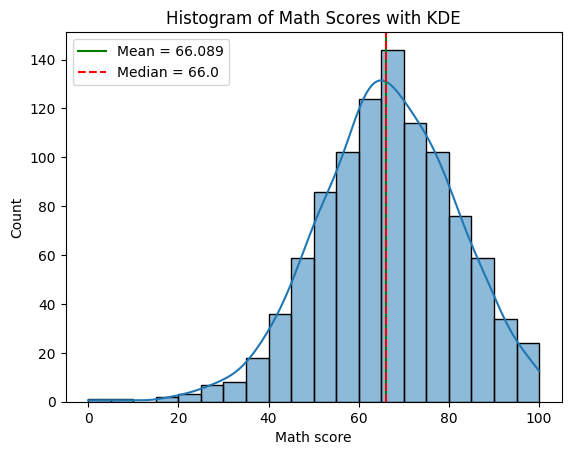

In [124]:
sns.histplot(df["math_score"], kde=True, bins=20)
plt.axvline(df["math_score"].median(), color="green", linestyle="-",label=f"Mean = {df['math_score'].mean()}")
plt.axvline(df["math_score"].mean(), color="red", linestyle="--",label = f"Median = {df['math_score'].median()}")
plt.title("Histogram of Math Scores with KDE")
plt.xlabel("Math score")
plt.legend()
plt.show()


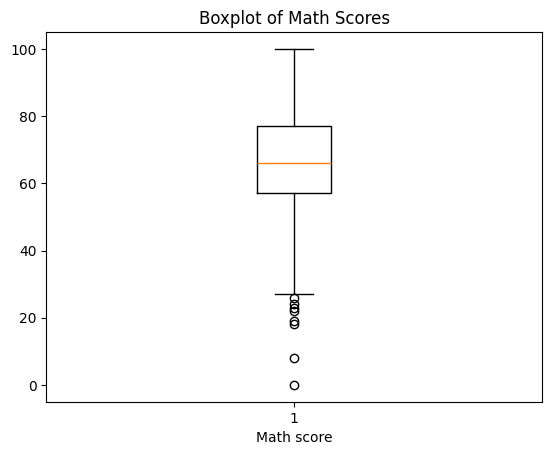

In [125]:
plt.boxplot(df["math_score"])
plt.title("Boxplot of Math Scores")
plt.xlabel("Math score")
plt.show()

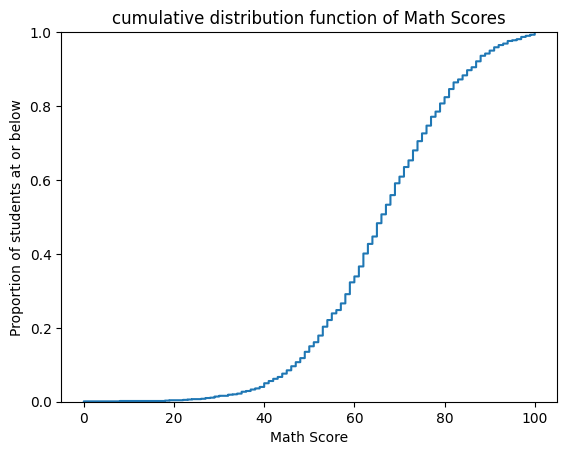

In [126]:
plt.ecdf(df["math_score"])
plt.title ("cumulative distribution function of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Proportion of students at or below")
plt.show()

In [127]:
normal_test_result = stats.normaltest(df["math_score"])
if normal_test_result.pvalue < 0.05:
  print (f"Not Normal Distrubution, pvalue = {round(normal_test_result.pvalue,6)}")
else:
  print (f"Normal Distrubution, pvalue = {round(normal_test_result.pvalue,6)}")

Not Normal Distrubution, pvalue = 0.000451


In [128]:
print (f"yes! mean and median values are very close to each other (mean-median):{df["math_score"].mean(),df["math_score"].median()}")
print (f"it's negtivaly skewed: {df["math_score"].skew().round(2)} means the distribution is shifted to the right")
print (f"Kurtosis is 0.28, only slightly above 0, so the tails are close to those of a normal distribution with marginally more extreme values")
print ("CDF tells you what fraction of students scored this or below, for example for the precentage of student score below 50 is approximatly 0.15")
print ("Noramality test give p = 0.00045, which is below 0.05, that means it's a significat --> not normal,\n"
  "the shape statistics tell a milder story: skewness is −0.28 and kurtosis is 0.28, both near zero,\nand the mean (66.09)"
   "and median (66.0) are almost identical. The distribution is therefore close to symmetric and bell-shaped, but not exactly normal.")

yes! mean and median values are very close to each other (mean-median):(np.float64(66.089), 66.0)
it's negtivaly skewed: -0.28 means the distribution is shifted to the right
Kurtosis is 0.28, only slightly above 0, so the tails are close to those of a normal distribution with marginally more extreme values
CDF tells you what fraction of students scored this or below, for example for the precentage of student score below 50 is approximatly 0.15
Noramality test give p = 0.00045, which is below 0.05, that means it's a significat --> not normal,
the shape statistics tell a milder story: skewness is −0.28 and kurtosis is 0.28, both near zero,
and the mean (66.09)and median (66.0) are almost identical. The distribution is therefore close to symmetric and bell-shaped, but not exactly normal.


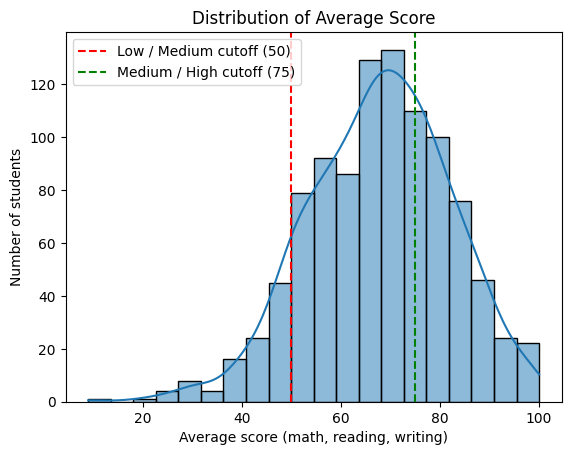

In [129]:
ax = sns.histplot(df["average_score"], bins=20, kde=True)
ax.axvline(50, color="red", linestyle="--", label="Low / Medium cutoff (50)")
ax.axvline(75, color="green", linestyle="--", label="Medium / High cutoff (75)")
ax.set_title("Distribution of Average Score")
ax.set_xlabel("Average score (math, reading, writing)")
ax.set_ylabel("Number of students")
ax.legend()
plt.show()

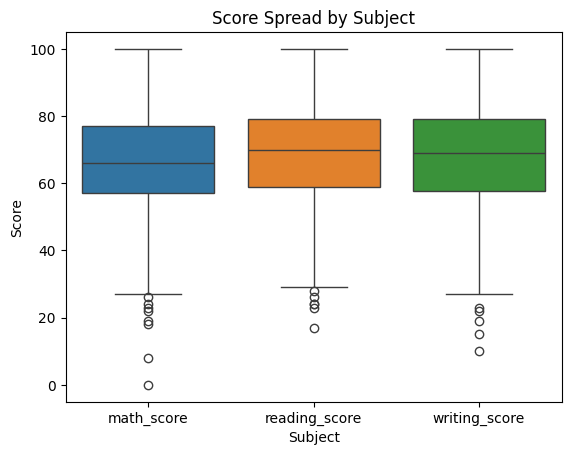

writing_score    15.20
math_score       15.16
reading_score    14.60
dtype: float64


In [130]:
subjects = df[["math_score", "reading_score", "writing_score"]]

ax = sns.boxplot(data=subjects)
ax.set_title("Score Spread by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Score")
plt.show()

print(subjects.std().round(2).sort_values(ascending=False))

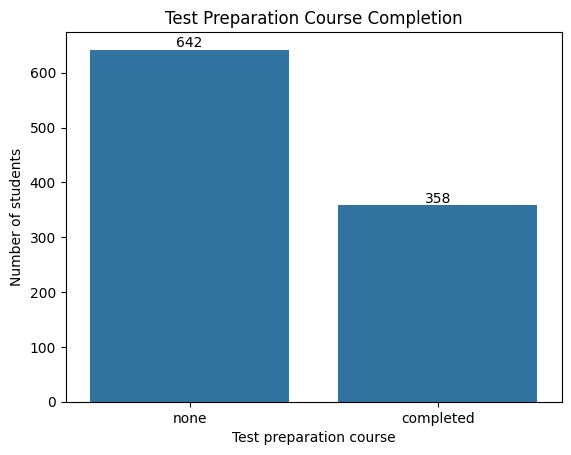

In [131]:
ax = sns.countplot(data=df, x="test_preparation_course")
ax.bar_label(ax.containers[0])
ax.set_title("Test Preparation Course Completion")
ax.set_xlabel("Test preparation course")
ax.set_ylabel("Number of students")
plt.show()

/tmp/ipykernel_510/3014804110.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(i, pct[i], pct[i].round(2))


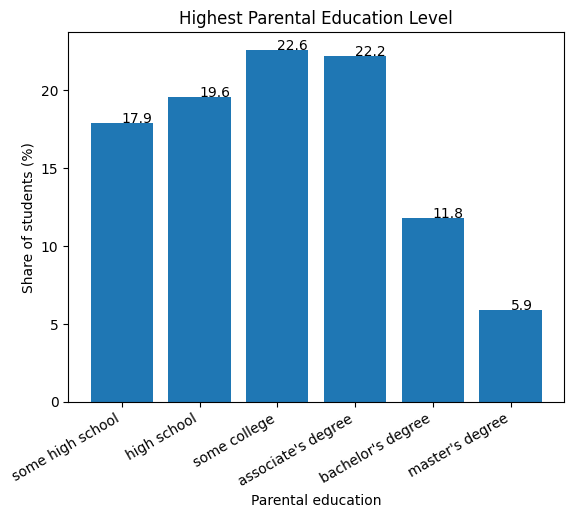

In [132]:
order = ["some high school", "high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]
pct = df["parental_level_of_education"].value_counts(normalize=True).reindex(order) * 100

plt.bar(order,pct)
for i in range(len(order)):
    plt.text(i, pct[i], pct[i].round(2))
plt.title("Highest Parental Education Level")
plt.xlabel("Parental education")
plt.ylabel("Share of students (%)")
plt.xticks(rotation=30, ha="right")
plt.show()

In [133]:
for c in ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]:
    print(df[c].value_counts(normalize=True).mul(100).round(1), "\n")

gender
female    51.8
male      48.2
Name: proportion, dtype: float64 

race_ethnicity
group C    31.9
group D    26.2
group B    19.0
group E    14.0
group A     8.9
Name: proportion, dtype: float64 

parental_level_of_education
some college          22.6
associate's degree    22.2
high school           19.6
some high school      17.9
bachelor's degree     11.8
master's degree        5.9
Name: proportion, dtype: float64 

lunch
standard        64.5
free/reduced    35.5
Name: proportion, dtype: float64 

test_preparation_course
none         64.2
completed    35.8
Name: proportion, dtype: float64 



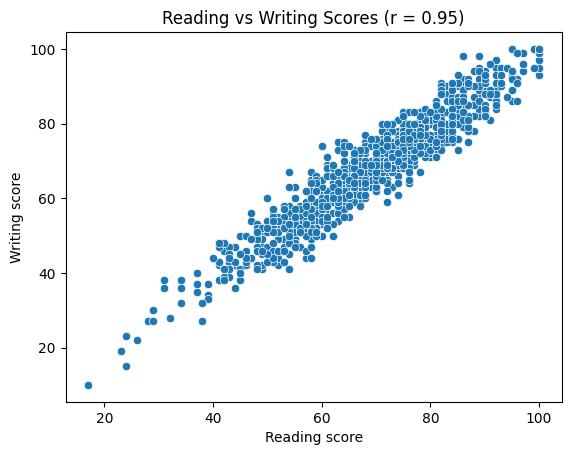

In [134]:
r = df["reading_score"].corr(df["writing_score"])
ax = sns.scatterplot(data=df, x="reading_score", y="writing_score")
ax.set_title(f"Reading vs Writing Scores (r = {r:.2f})")
ax.set_xlabel("Reading score")
ax.set_ylabel("Writing score")
plt.show()

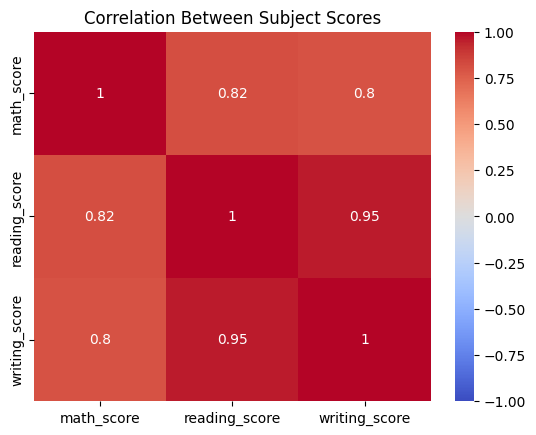

In [135]:
corr = df[["math_score", "reading_score", "writing_score"]].corr()
ax = sns.heatmap(corr, annot=True,  cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation Between Subject Scores")
plt.show()

In [136]:
scores = ["math_score", "reading_score", "writing_score", "average_score"]

for col in ["test_preparation_course", "lunch", "gender"]:
    display(df.groupby(col)[scores].mean().round(1))

display(df.groupby("parental_level_of_education")[scores].mean().round(1).reindex(order))

,math_score,reading_score,writing_score,average_score
test_preparation_course,,,,
completed,69.7,73.9,74.4,72.7
none,64.1,66.5,64.5,65.0


,math_score,reading_score,writing_score,average_score
lunch,,,,
free/reduced,58.9,64.7,63.0,62.2
standard,70.0,71.7,70.8,70.8


,math_score,reading_score,writing_score,average_score
gender,,,,
female,63.6,72.6,72.5,69.6
male,68.7,65.5,63.3,65.8


,math_score,reading_score,writing_score,average_score
parental_level_of_education,,,,
some high school,63.5,66.9,64.9,65.1
high school,62.1,64.7,62.4,63.1
some college,67.1,69.5,68.8,68.5
associate's degree,67.9,70.9,69.9,69.6
bachelor's degree,69.4,73.0,73.4,71.9
master's degree,69.7,75.4,75.7,73.6


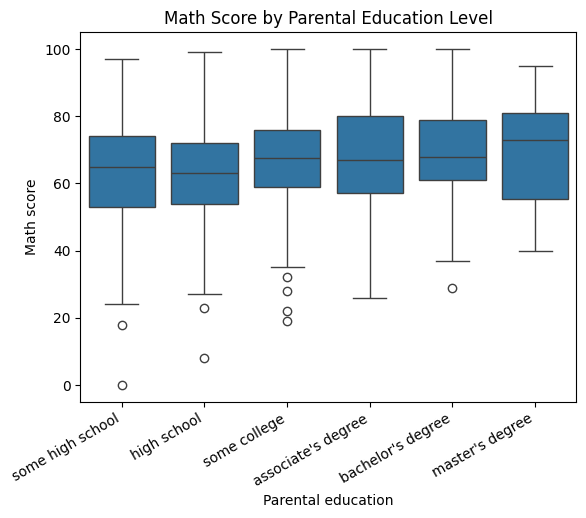

In [137]:
ax = sns.boxplot(data=df, x="parental_level_of_education", y="math_score", order=order)
ax.set_title("Math Score by Parental Education Level")
ax.set_xlabel("Parental education")
ax.set_ylabel("Math score")
plt.xticks(rotation=30, ha="right")
plt.show()

In [145]:
prep = df[df["test_preparation_course"] == "completed"]
no_prep = df[df["test_preparation_course"] == "none"]

for col in ["math_score", "reading_score", "writing_score"]:
    p_norm = (stats.normaltest(prep[col]).pvalue, stats.normaltest(no_prep[col]).pvalue)
    p_lev = stats.levene(prep[col], no_prep[col]).pvalue
    equal_var = p_lev >= 0.05
    t = stats.ttest_ind(prep[col], no_prep[col], equal_var=equal_var)
    print(f"{col}: normality p = {p_norm[0].round(3)} / {p_norm[1].round(3)} | "
          f"Levene p = {p_lev.round(3)} -> equal_var = {equal_var} | p-value = {t.pvalue.round(3)}")

math_score: normality p = 0.433 / 0.001 | Levene p = 0.466 -> equal_var = True | p-value = 0.0
reading_score: normality p = 0.026 / 0.05 | Levene p = 0.299 -> equal_var = True | p-value = 0.0
writing_score: normality p = 0.023 / 0.075 | Levene p = 0.015 -> equal_var = False | p-value = 0.0


In [139]:
print ("Test preparation. Students who completed it score higher in every subject: math +5.6, reading +7.4, writing +9.9 points\n")
print ("Reading and writing. Strongly related, r = 0.95. They’re measuring nearly the same skill. Math is the more independent subject.\n")
print ("Parental education. Broadly yes. The average score rises from 63.1 (high school) to 73.6 (master’s). But it isn’t perfectly ordered: some high school (65.1) beats high school (63.1).\n")
print ("Lunch and gender:-\n"
"Lunch: standard-lunch students score higher in all three subjects. The math gap is 11.1 points, the largest math gap of any variable in the dataset.\n"
"Gender: the direction depends on the subject. Males score +5.1 in math; females score +7.1 in reading and +9.2 in writing. If you compared averages only, you’d miss that the gap reverses in math. This is why you break results down by subject.")

Test preparation. Students who completed it score higher in every subject: math +5.6, reading +7.4, writing +9.9 points

Reading and writing. Strongly related, r = 0.95. They’re measuring nearly the same skill. Math is the more independent subject.

Parental education. Broadly yes. The average score rises from 63.1 (high school) to 73.6 (master’s). But it isn’t perfectly ordered: some high school (65.1) beats high school (63.1).

Lunch and gender:-
Lunch: standard-lunch students score higher in all three subjects. The math gap is 11.1 points, the largest math gap of any variable in the dataset.
Gender: the direction depends on the subject. Males score +5.1 in math; females score +7.1 in reading and +9.2 in writing. If you compared averages only, you’d miss that the gap reverses in math. This is why you break results down by subject.
